# Statistics for the Report

This notebook computes the numbers in the report that do not come from `src/train.py` or `src/evaluate.py`:

1. the exact duplicate images in the CIFAR-100 training set (Section 2.2),
2. the trainable parameter count of each model (Section 4.2),
3. McNemar tests with a Bonferroni correction comparing the three models (Sections 5 and 8).

It reads the CIFAR-100 data from `data/` and the test predictions that `src/evaluate.py` saves to `logs/`, so it has to run from the repository root.

## Setup

Mount Google Drive, move to the repository root so `src` can be imported and the relative paths work, and import everything the notebook uses.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/assignments/Vision_Transformers
import os
import torch
from itertools import combinations
import numpy as np
from scipy.stats import chi2
import matplotlib.pyplot as plt
import torchvision

from src.data import image_hash_groups

from src.build import build_model

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/assignments/Vision_Transformers


### Environment

Pull the latest code, install the pinned requirements, load the W&B API key, and print the library versions used for the pins in `requirements.txt`.

In [2]:
!git pull
%pip install -q -r requirements.txt
with open("/content/drive/MyDrive/credentials/wandb_api.txt") as f:
    os.environ["WANDB_API_KEY"] = f.read().strip()
    print("W&B key loaded:", len(os.environ.get("WANDB_API_KEY", "")) > 0)
# Check for PyTorch and CUDA availability
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
!pip freeze | grep -E "torch|numpy|scikit|wandb"
!pip freeze | grep -iE "^(pytest|pandas|matplotlib|tqdm|pylint|scipy)=="
!python --version

Already up to date.
W&B key loaded: True
PyTorch version: 2.11.0+cu130
CUDA available: True
numpy==2.4.6
scikit-image==0.25.2
scikit-learn==1.6.1
torch==2.11.0
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.17.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.26.0
wandb==0.28.1
matplotlib==3.10.0
pandas==2.2.3
pylint==4.1.3
pytest==8.4.2
scipy==1.16.3
tqdm==4.67.3
Python 3.13.16


## Duplicate Training Set Images

Each training image is hashed with MD5 over its raw pixels using `image_hash_groups` from `src/data.py`. Images with identical pixels get the same hash, so any hash shared by more than one index is a group of exact duplicates. Near-duplicates (shifted, cropped, or recolored copies) hash differently and are not found.

The training set has 14 duplicate pairs, leaving 49,986 unique images out of 50,000. After the 5,000 validation images are split off, all 14 pairs are in the training split, which has 44,986 unique images. Nine of the pairs have conflicting labels, for example the same image labeled both seal and otter, or both snake and worm.

14 duplicate groups, 49986 unique images
[4348, 30931] ['aquarium_fish', 'aquarium_fish']
[8393, 36874] ['girl', 'baby']
[8599, 22657] ['aquarium_fish', 'aquarium_fish']
[9012, 31128] ['otter', 'seal']
[16646, 31828] ['mouse', 'shrew']
[17688, 41874] ['seal', 'otter']
[18461, 46752] ['snake', 'worm']
[20635, 32666] ['aquarium_fish', 'aquarium_fish']
[23947, 33638] ['seal', 'otter']
[25218, 46851] ['aquarium_fish', 'aquarium_fish']
[27737, 47636] ['snake', 'worm']
[28293, 41860] ['aquarium_fish', 'aquarium_fish']
[30418, 47806] ['spider', 'crab']
[31227, 34187] ['whale', 'shark']


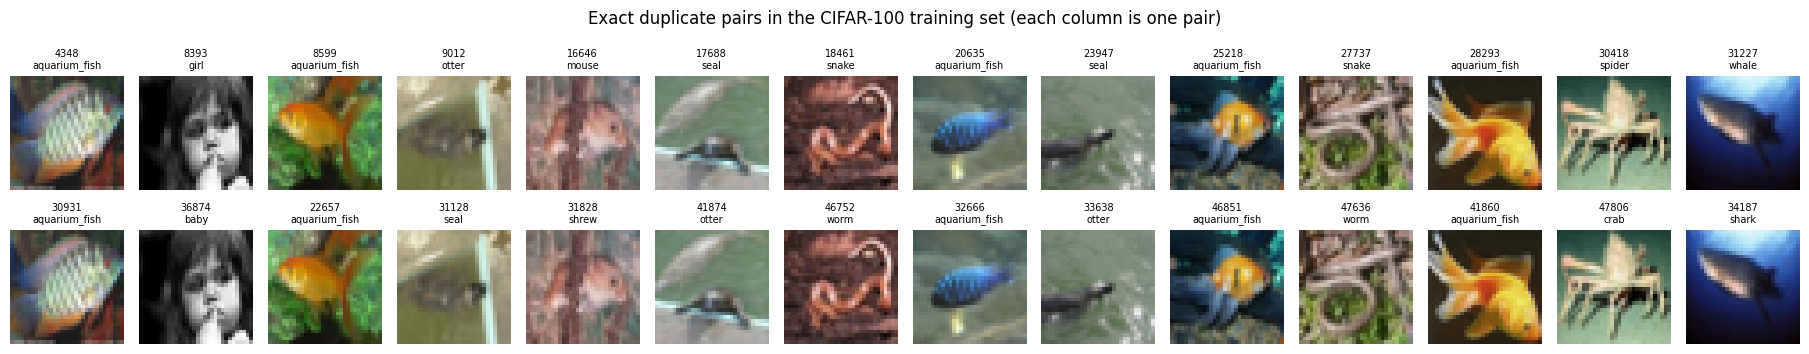

In [3]:
train_set = torchvision.datasets.CIFAR100(root="data", train=True, download=False)

# Groups of training images with identical pixels
groups = image_hash_groups(train_set.data)
duplicates = [indices for indices in groups.values() if len(indices) > 1]
n_unique = len(train_set.data) - sum(len(indices) - 1 for indices in duplicates)
print(f"{len(duplicates)} duplicate groups, {n_unique} unique images")
for indices in duplicates:
    print(indices, [train_set.classes[train_set.targets[i]] for i in indices])

# One column per pair; each image is titled with its index and label
fig, axes = plt.subplots(2, len(duplicates), figsize=(1.3 * len(duplicates), 3.8))
for col, indices in enumerate(duplicates):
    for row, idx in enumerate(indices[:2]):
        axes[row, col].imshow(train_set.data[idx])
        axes[row, col].set_title(f"{idx}\n{train_set.classes[train_set.targets[idx]]}", fontsize=7)
        axes[row, col].axis("off")
fig.suptitle("Exact duplicate pairs in the CIFAR-100 training set (each column is one pair)")
fig.tight_layout()
plt.show()

## Model Parameters

Builds each model with the settings it was trained with and counts its trainable parameters. Buffers, such as BatchNorm running statistics and the Swin's relative position index and shift masks, are not included. The counts are Plain ViT 4,799,076, Hybrid 4,604,084, and Swin 4,247,064, matching the hand calculations in Section 4.2 after the buffers are removed.

In [4]:
models = {
    "Plain ViT": {"arch": "vit", "tokenizer": "patch", "depth": 9, "drop_path_rate": 0.1},
    "Hybrid": {"arch": "vit", "tokenizer": "resnet", "depth": 7, "drop_path_rate": 0.1},
    "Swin": {"arch": "swin", "drop_path_rate": 0.1},
}

for name, settings in models.items():
    model = build_model(settings)
    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
    print(f"{name}: {total_parameters:,}")

Plain ViT: 4,799,076
Hybrid: 4,604,084
Swin: 4,247,064


## McNemar Test and Bonferroni Correction

All three models were evaluated on the same 10,000 test images, so they are compared with McNemar's test on their paired predictions. For two models A and B, only the images where they disagree are counted:

- $b$: images A got right and B got wrong
- $c$: images B got right and A got wrong

If the two models were equally accurate, $b$ and $c$ would be about the same. The test statistic, with continuity correction, is

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c},$$

compared to a chi-square distribution with 1 degree of freedom. Because three pairwise tests are run, each p-value is multiplied by 3 (Bonferroni correction) to keep the overall chance of a false positive at or below 0.05.

The hybrid is significantly better than both the plain ViT and the Swin. The plain ViT and the Swin are not significantly different after the correction (p = 0.127).

In [5]:
runs = {"Hybrid": "hybrid_seed2026", "Plain ViT": "vit_seed2026", "Swin": "swin_seed2026"}

# Which test images each model got right
correct = {}
labels = None
for name, run in runs.items():
    preds_file = np.load(f"logs/{run}_test_preds.npz")
    if labels is None:
        labels = preds_file["labels"]
    assert np.array_equal(preds_file["labels"], labels), f"{run}: labels differ"
    correct[name] = preds_file["preds"] == labels

pairs = list(combinations(runs, 2))
print(f"{'Pair':<20}{'b':>6}{'c':>6}{'chi2':>9}{'p':>12}{'Bonferroni p':>15}")
for model_a, model_b in pairs:
    # b: A right and B wrong; c: B right and A wrong
    b = np.sum(correct[model_a] & ~correct[model_b])
    c = np.sum(~correct[model_a] & correct[model_b])
    stat = (abs(b - c) - 1) ** 2 / (b + c)  # continuity correction
    p = chi2.sf(stat, df=1)
    p_adjusted = min(1.0, len(pairs) * p)
    print(f"{model_a + ' vs ' + model_b:<20}{b:>6}{c:>6}{stat:>9.1f}{p:>12.3g}{p_adjusted:>15.3g}")

Pair                     b     c     chi2           p   Bonferroni p
Hybrid vs Plain ViT   1127   620    146.6    9.81e-34       2.94e-33
Hybrid vs Swin        1177   592    192.8     7.8e-44       2.34e-43
Plain ViT vs Swin      758   680      4.1      0.0423          0.127


## Conclusion

- **Duplicates:** The CIFAR-100 training set has 14 exact duplicate pairs, so the 45,000-image training split has 44,986 unique images. This is the $n_{\text{train}}$ used for $\kappa$ and $\rho$ in Section 4.3. Nine of the pairs have conflicting labels, mostly between classes the models also confuse at test time (seal and otter, snake and worm, mouse and shrew).
- **Parameters:** The plain ViT (4,799,076) is 4.2% larger and the Swin (4,247,064) is 7.8% smaller than the hybrid (4,604,084), so both comparison models are within the required 10% of the primary model.
- **Significance:** The hybrid is significantly more accurate than both the plain ViT ($\chi^2 = 145.9$) and the Swin ($\chi^2 = 192.2$), with Bonferroni-corrected p-values far below 0.05. The plain ViT and the Swin are not significantly different after the correction ($p = 0.127$), so their 0.78-point gap in test accuracy may be due to chance.